Let's do PCA analysis.

The first step is to make sure that there are no missing data in the dataset. To do this, we need to spatially interpolate the missing data using the calculated decorrelation scale.

Because each station has different decorrelation scales, we need to interpolate the missing data for each station separately.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import os
import sys
from pathlib import Path
import yaml

# Ensure local scripts are importable
project_root = Path("../../").resolve()
sys.path.append(str(project_root))

from scripts.data_loader import load_and_process_data, load_raw_shapefiles
from scripts.paths import ProjectPaths

print("Project Root:", project_root)

# Set force_reload=True if you added new raw data or changed the cleaning logic
merged_gdf = load_and_process_data(force_reload=True)

# Add Regional Filtering (Add this right after loading)
try:
    import yaml
    with open('../../params.yaml', 'r') as f:
        params = yaml.safe_load(f)
    TARGET_REGION = params['mapping']['target_region']
    REGION_COLUMN = params['mapping']['region_column']
    
    # Filter the dataset
    initial_count = len(merged_gdf)
    merged_gdf = merged_gdf[merged_gdf[REGION_COLUMN] == TARGET_REGION].copy()
    print(f"Filtered for {TARGET_REGION}: {initial_count} -> {len(merged_gdf)} rows")
except Exception as e:
    print(f"Regional filtering skipped or failed: {e}")

# Filter summer bottom do data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2) &
    (merged_gdf[REGION_COLUMN] == TARGET_REGION)
].dropna(subset=['do_']).copy()

# Convert do_ to numeric
summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')

Project Root: /home/reyha/SIS_Analysis_WSL
Loading raw shapefiles from 1981 to 2023...
Merging 171 shapefiles...
Processing data (detecting V2 parameters, cleaning DO, adding seasons)...
Mapped ph2 -> ph (ph2: 62738 valid float entries | ph: 62480 valid originally)
Mapped do_2 -> do_ (do_2: 62738 valid float entries | do_: 62472 valid originally)
Mapped salt2 -> salt (salt2: 62738 valid float entries | salt: 59945 valid originally)
Mapped cod2 -> cod (cod2: 62738 valid float entries | cod: 62336 valid originally)
Mapped rcod2 -> rcod (rcod2: 62738 valid float entries | rcod: 31889 valid originally)
Mapped nh4n2 -> nh4n (nh4n2: 62738 valid float entries | nh4n: 59605 valid originally)
Mapped no2n2 -> no2n (no2n2: 62738 valid float entries | no2n: 59360 valid originally)
Mapped no3n2 -> no3n (no3n2: 62738 valid float entries | no3n: 59865 valid originally)
Mapped tn2 -> tn (tn2: 62738 valid float entries | tn: 62211 valid originally)
Mapped po4p2 -> po4p (po4p2: 62738 valid float entries

In [5]:
# Parameters
weighting_func = 'gaussian'
min_weight = 0.01
search_radius_factor = 2.0
subset_dir = str(ProjectPaths.get_subset_dir('Summer', 'bottom'))  # default subset

In [6]:
# Load datasets from 08_Decorrelation_Analysis_v3.ipynb
from pathlib import Path
subset_path = Path(subset_dir)

yearly_do_df = pd.read_csv(subset_path / "yearly_do_df.csv", index_col=0)
yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)

dist_matrix_km = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / "dist_matrix_km.csv", index_col=0)
dist_matrix_km.index = dist_matrix_km.index.astype(str).str.zfill(8)
dist_matrix_km.columns = dist_matrix_km.columns.astype(str).str.zfill(8)

decorrelation_df = pd.read_csv(subset_path / "stations_decorrelation_scale.csv", index_col=0)
decorrelation_df.index = decorrelation_df.index.astype(str).str.zfill(8)

print(f"Loaded data from: {subset_path}")
print(f"Yearly DO: {yearly_do_df.shape}, Distance matrix: {dist_matrix_km.shape}, Decorrelation: {decorrelation_df.shape}")

Loaded data from: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom
Yearly DO: (124, 41), Distance matrix: (124, 124), Decorrelation: (124, 7)


In [7]:
# Define weight functions

def exponential_weight(distance, scale):
    return np.exp(-distance / scale)

def gaussian_weight(distance, scale):
    return np.exp(-(distance**2) / (2 * scale**2))

In [8]:
# Define Interpolation function 

def interpolate_missing_do(yearly_do_df, decorrelation_df, dist_matrix, 
                            weighting_func='exponential', min_weight=0.01):
    """
    Interpolate missing DO values using neighboring stations.
    
    Search radius is set to 2x the station's decorrelation scale.
    Only neighbors within this radius are considered.
    """
    interpolated_df = yearly_do_df.copy()
    common_stations = list(set(yearly_do_df.index) & set(decorrelation_df.index) & set(dist_matrix.index))
    filled_count = 0
    
    for year in yearly_do_df.columns:
        for station in common_stations:
            if not pd.isna(yearly_do_df.loc[station, year]):
                continue
            scale = decorrelation_df.loc[station, 'Decorrelation_Scale_km']
            if pd.isna(scale) or scale <= 0:
                continue
            
            # Set search radius to 2x decorrelation scale
            search_radius = search_radius_factor * scale
            
            valid_stations = yearly_do_df.index[~pd.isna(yearly_do_df[year])].tolist()
            neighbors = [s for s in valid_stations if s in common_stations and s != station]
            if len(neighbors) == 0:
                continue
            
            distances = dist_matrix.loc[station, neighbors]
            
            # Filter neighbors within search radius
            within_radius = distances[distances <= search_radius]
            if len(within_radius) == 0:
                continue
            
            neighbors_in_radius = within_radius.index.tolist()
            
            # Get values and distances for neighbors in radius
            dist_vals = dist_matrix.loc[station, neighbors_in_radius].values  # numpy array
            do_vals = yearly_do_df.loc[neighbors_in_radius, year].values      # numpy array
            
            # Calculate weights (numpy operations)
            if weighting_func == 'exponential':
                weight_vals = exponential_weight(dist_vals, scale)
            else:
                weight_vals = gaussian_weight(dist_vals, scale)
            
            # Filter by minimum weight
            valid_mask = weight_vals > min_weight
            if valid_mask.sum() == 0:
                continue
            
            # Weighted average using numpy arrays (no index alignment issues)
            interpolated_df.loc[station, year] = (do_vals[valid_mask] * weight_vals[valid_mask]).sum() / weight_vals[valid_mask].sum()
            filled_count += 1
    
    print(f"Filled {filled_count} missing values (search radius = 2x decorrelation scale)")
    return interpolated_df

In [9]:
# Appy interpolation on data

missing_before = yearly_do_df.isna().sum().sum()
interpolated_do_df = interpolate_missing_do(yearly_do_df, decorrelation_df, dist_matrix_km, weighting_func='gaussian')
missing_after = interpolated_do_df.isna().sum().sum()

print(f"Before: {missing_before}, After: {missing_after}, Filled: {missing_before - missing_after}")

Filled 53 missing values (search radius = 2x decorrelation scale)
Before: 73, After: 20, Filled: 53


In [10]:
# Save interpolated data to the subset directory
from pathlib import Path
out_path = Path(subset_dir) / 'interpolated_do_df.csv'
interpolated_do_df.to_csv(out_path, index=True)
print(f"Saved interpolated DO to: {out_path}")

Saved interpolated DO to: /home/reyha/SIS_Analysis_WSL/data/processed/seasonal/summer_bottom/interpolated_do_df.csv


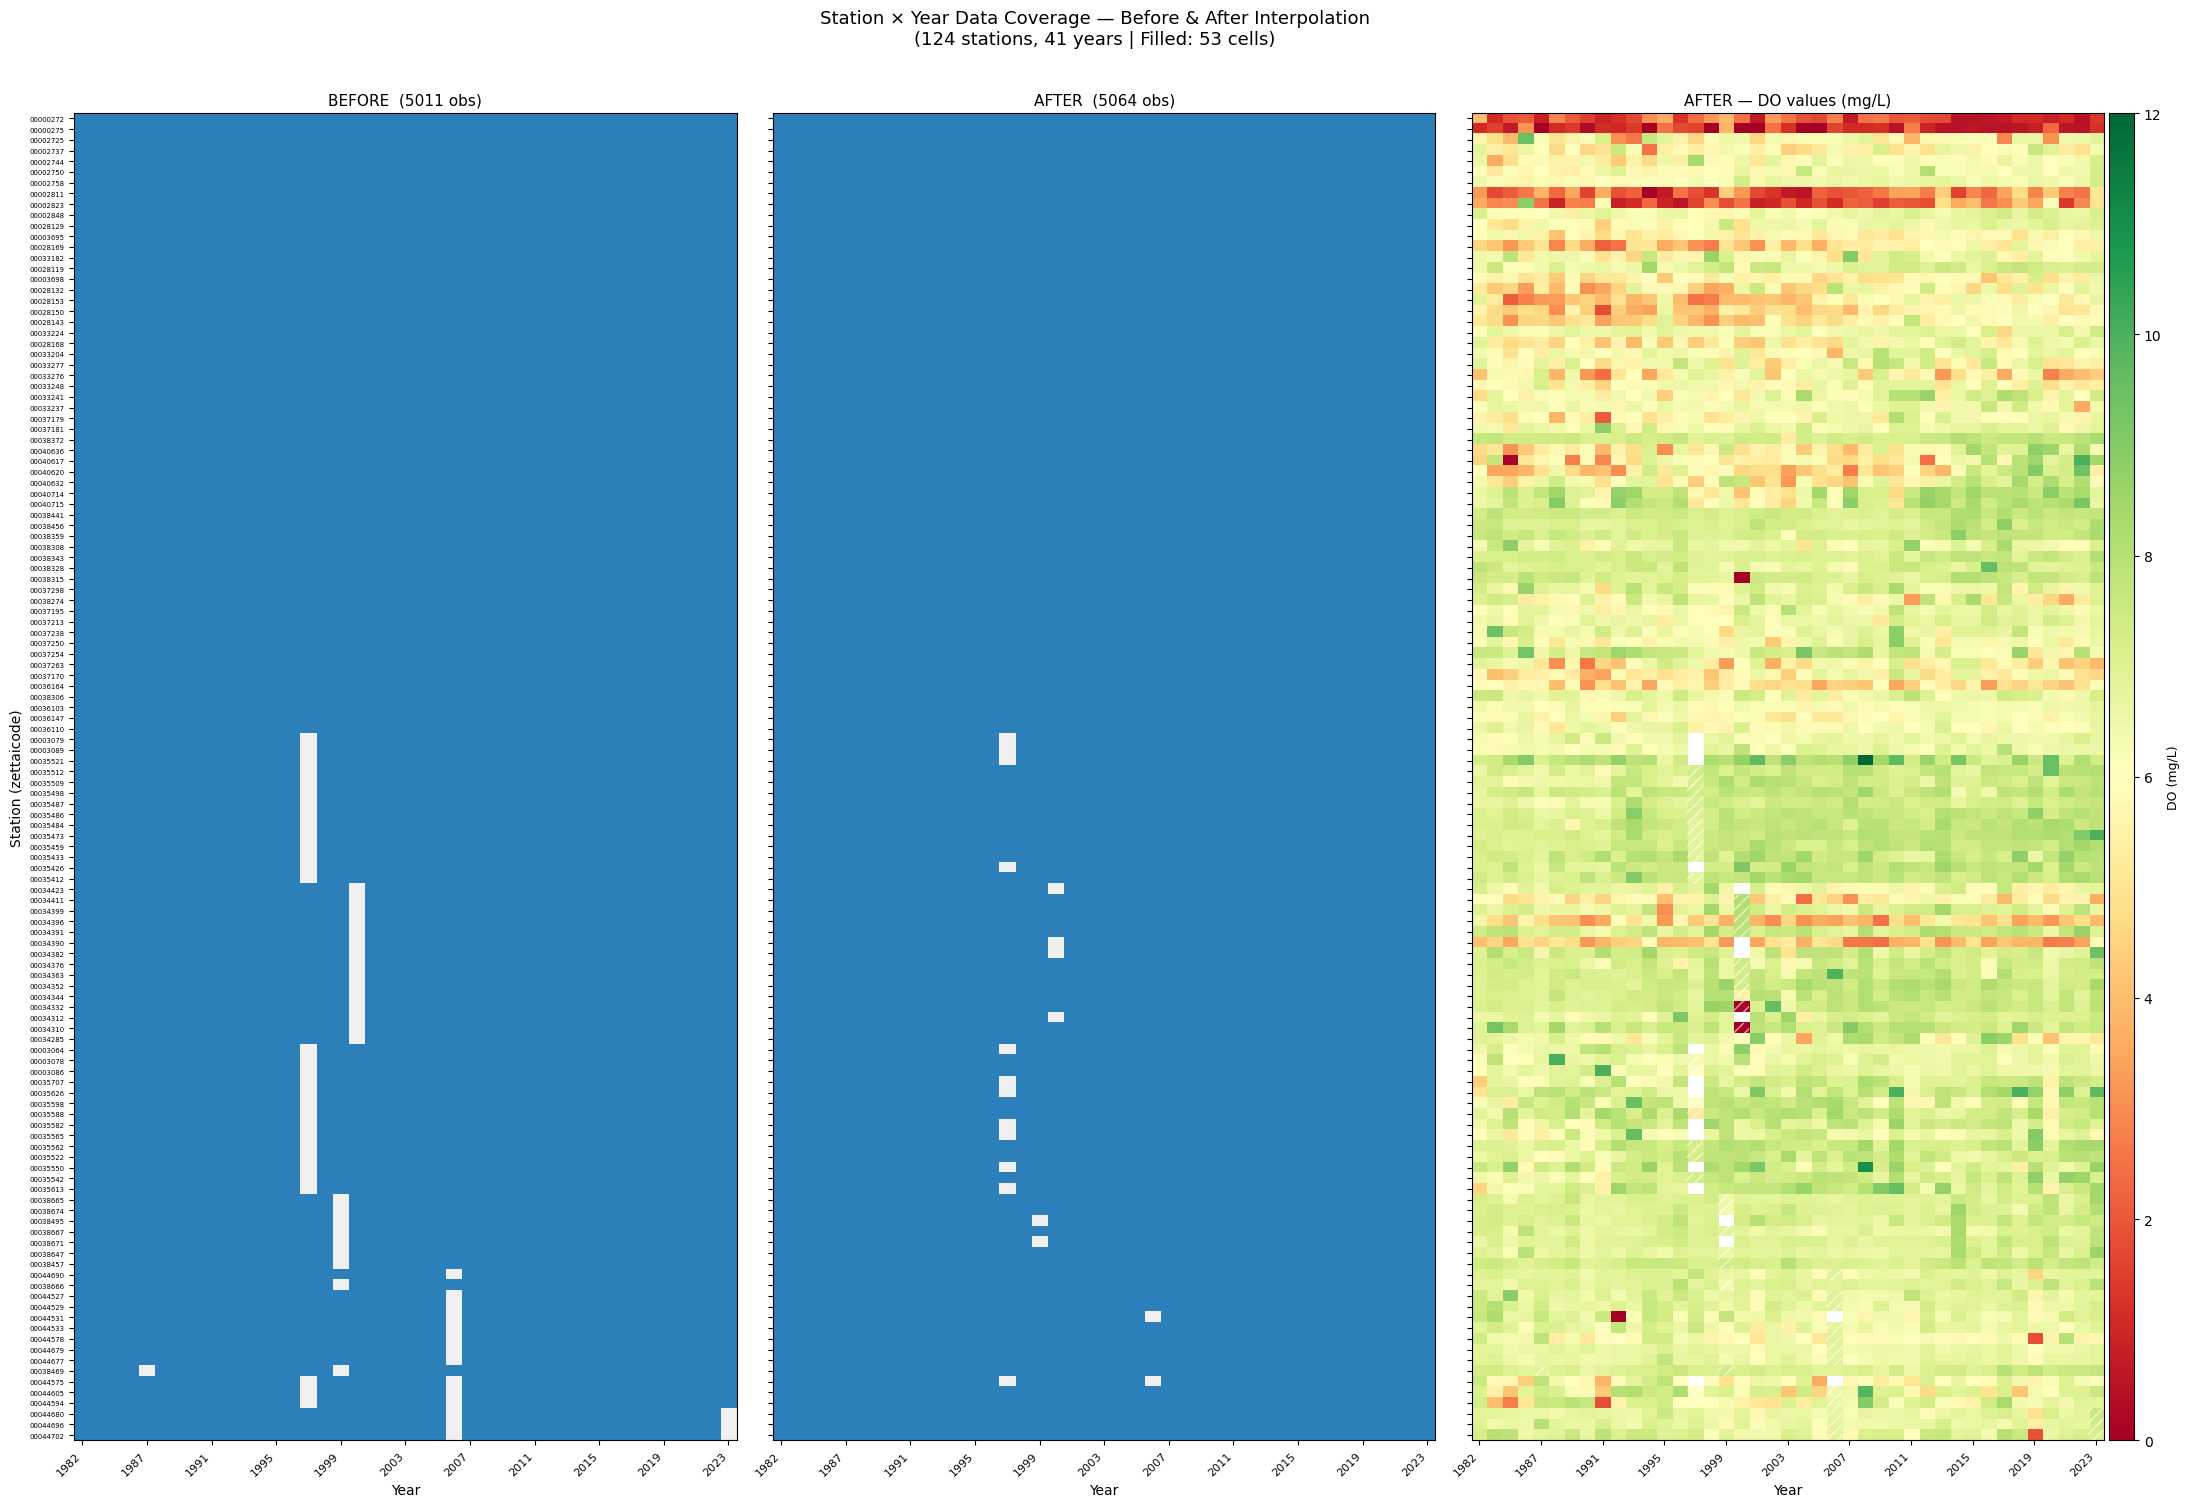

── Data Coverage Summary ──────────────────────────────
  Matrix size  : 124 stations × 41 years = 5084 cells
  Before       :  5011 obs  (98.6% complete)
  After        :  5064 obs  (99.6% complete)
  Interpolated :    53 cells filled
  Still missing:    20 cells (cannot be interpolated)


In [11]:
# ─── Visualize: Yearly Station Data Before & After Interpolation ─────────────

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np

# ── Build heatmap matrices ───────────────────────────────────────────────────
# Sort stations consistently in both DataFrames
all_stations = sorted(yearly_do_df.index.union(interpolated_do_df.index))
years = sorted([int(c) for c in yearly_do_df.columns])

before = yearly_do_df.reindex(index=all_stations, columns=[str(y) for y in years])
after  = interpolated_do_df.reindex(index=all_stations, columns=[str(y) for y in years])

# Sort stations by total data coverage (most complete → top)
coverage_order = before.notnull().sum(axis=1).sort_values(ascending=False).index
before = before.loc[coverage_order]
after  = after.loc[coverage_order]

# Binary mask: 1 = data present, 0 = missing
before_mask = before.notnull().astype(float)  # NaN → 0
after_mask  = after.notnull().astype(float)

# ── Figure layout ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    1, 3,
    figsize=(22, max(8, len(all_stations) * 0.12)),
    gridspec_kw={"width_ratios": [1, 1, 1]},
    sharey=True,
)
fig.suptitle(
    f"Station × Year Data Coverage — Before & After Interpolation\n"
    f"({len(all_stations)} stations, {len(years)} years | "
    f"Filled: {int(after_mask.sum().sum() - before_mask.sum().sum())} cells)",
    fontsize=13, y=1.01,
)

cmap_binary = plt.cm.colors.ListedColormap(["#f0f0f0", "#2c7fb8"])  # grey / blue
cmap_do     = plt.cm.RdYlGn  # red-yellow-green for DO values
vmin, vmax  = 0.0, 12.0      # typical DO range (mg/L)

tick_step = max(1, len(years) // 10)          # show ~10 year labels
year_ticks = np.arange(0, len(years), tick_step)
year_labels = [str(years[i]) for i in year_ticks]

def _label_axes(ax, title, ylabel=False):
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Year", fontsize=10)
    ax.set_xticks(year_ticks)
    ax.set_xticklabels(year_labels, rotation=45, ha="right", fontsize=8)
    if ylabel:
        ax.set_ylabel("Station (zettaicode)", fontsize=10)
    ax.set_yticks(np.arange(len(all_stations)))
    ax.set_yticklabels(coverage_order.tolist(), fontsize=5)

# ── Panel 1: BEFORE (binary presence/absence) ────────────────────────────────
ax0 = axes[0]
ax0.imshow(before_mask.values, aspect="auto", cmap=cmap_binary,
           vmin=0, vmax=1, interpolation="nearest")
_label_axes(ax0, f"BEFORE  ({int(before_mask.sum().sum())} obs)", ylabel=True)

# ── Panel 2: AFTER (binary presence/absence) ─────────────────────────────────
ax1 = axes[1]
im_binary = ax1.imshow(after_mask.values, aspect="auto", cmap=cmap_binary,
                        vmin=0, vmax=1, interpolation="nearest")
_label_axes(ax1, f"AFTER  ({int(after_mask.sum().sum())} obs)")

# ── Panel 3: AFTER — actual DO values (colour-coded) ─────────────────────────
ax2 = axes[2]
im_do = ax2.imshow(after.values.astype(float), aspect="auto", cmap=cmap_do,
                   vmin=vmin, vmax=vmax, interpolation="nearest")
_label_axes(ax2, "AFTER — DO values (mg/L)")

# Overlay hatching on cells that were filled by interpolation
filled_mask = (after.notnull() & before.isnull()).values  # True where imputed
for r, c in np.argwhere(filled_mask):
    ax2.add_patch(plt.matplotlib.patches.Rectangle(
        (c - 0.5, r - 0.5), 1, 1,
        fill=False, hatch="///", linewidth=0,
        edgecolor="white", alpha=0.65,
    ))

# Colorbars
from mpl_toolkits.axes_grid1 import make_axes_locatable
div = make_axes_locatable(ax2)
cax = div.append_axes("right", size="4%", pad=0.05)
cb = fig.colorbar(im_do, cax=cax)
cb.set_label("DO (mg/L)", fontsize=9)

plt.tight_layout()
plt.show()

# ── Summary statistics ────────────────────────────────────────────────────────
n_before   = int(before_mask.sum().sum())
n_after    = int(after_mask.sum().sum())
n_filled   = n_after - n_before
n_total    = before_mask.size
pct_before = n_before / n_total * 100
pct_after  = n_after  / n_total * 100

print("── Data Coverage Summary ──────────────────────────────")
print(f"  Matrix size  : {len(all_stations)} stations × {len(years)} years = {n_total} cells")
print(f"  Before       : {n_before:>5d} obs  ({pct_before:.1f}% complete)")
print(f"  After        : {n_after:>5d} obs  ({pct_after:.1f}% complete)")
print(f"  Interpolated : {n_filled:>5d} cells filled")
print(f"  Still missing: {n_total - n_after:>5d} cells (cannot be interpolated)")


### Spatial Distribution of Data Sampling Coverage
Following the requested styling, we map the total count of non-NaN DO values for each station across all years.

Saved filtered sampling map to: /home/reyha/SIS_Analysis_WSL/figures/total_sampling_years_SIS_map.png


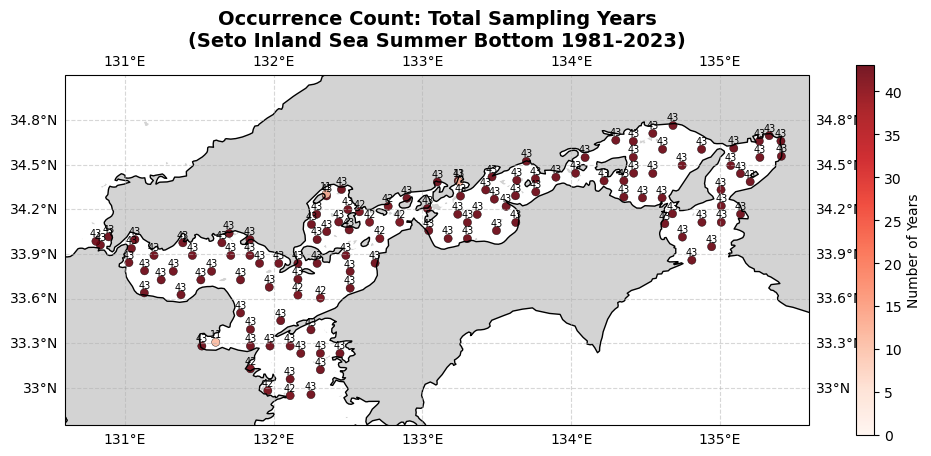

Total sampling points (SIS): 127
Max Sampling Years: 43


In [12]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
from scripts.paths import ProjectPaths

# --- NEW: Filter to remove Tokyo Bay and Ise Bay ---
# This ensures we only analyze and map the Seto Inland Sea region
sis_only_df = summer_bottom_df[summer_bottom_df['watermass_name'] == 'Seto Inland Sea'].copy()

# 1. Get list of all unique stations for mapping consistency (using filtered DF)
all_stations = sis_only_df[['zettaicode', 'geometry']].drop_duplicates('zettaicode')

# 2. Count non-NaN sampling years per station in the filtered sis_only_df
counts = sis_only_df.groupby('zettaicode')['year'].nunique().reset_index(name='sampling_count')

# Merge with all stations
plot_df = all_stations.merge(counts, on='zettaicode', how='left')
plot_df['sampling_count'] = plot_df['sampling_count'].fillna(0)

# === Plotting ===
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([130.6, 135.6, 32.75, 35.1], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.OCEAN, facecolor='white')
ax.coastlines()
ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)

# Plot points
max_val = plot_df['sampling_count'].max()
vmax = max(max_val, 1)

sc = ax.scatter(
    plot_df.geometry.x, plot_df.geometry.y, 
    s=35, alpha=0.9,
    c=plot_df['sampling_count'],
    cmap='Reds', 
    vmin=0, vmax=vmax,
    transform=ccrs.PlateCarree(),
    edgecolors='black', linewidth=0.3
)

# Add count labels above points
for idx, row in plot_df.iterrows():
    if row['sampling_count'] > 0:
        ax.text(row.geometry.x, row.geometry.y + 0.02, int(row['sampling_count']),
                fontsize=7, ha='center', va='bottom', transform=ccrs.PlateCarree())

# Title and Legend
plt.colorbar(sc, ax=ax, shrink=0.6, label='Number of Years')
ax.set_title('Occurrence Count: Total Sampling Years\n(Seto Inland Sea Summer Bottom 1981-2023)', fontsize=14, fontweight='bold')

# Save the plot
output_filename = "total_sampling_years_SIS_map.png"
output_path = ProjectPaths.FIGURES_DIR / output_filename
plt.savefig(output_path, dpi=300, bbox_inches='tight')
print(f"Saved filtered sampling map to: {output_path}")

plt.show()

print(f"Total sampling points (SIS): {len(plot_df)}")
print(f"Max Sampling Years: {int(vmax)}")